# Project: Used Car Price Prediction using Machine Learning

### Problem Statement
To predict the selling price of a used car based on its key features such as year, kilometers driven, fuel type, transmission, and more.

### Proposed Approach
1. **Data Loading & Exploration**: Read and understand the two datasets.
2. **Data Preprocessing & Cleaning**: Handle missing values, extract numerical quantities from string columns, and align structures.
3. **Exploratory Data Analysis (EDA)**: Plot relationships and understand the data distribution.
4. **Feature Engineering & Selection**: Prepare categorical variables for ML algorithms.
5. **Model Development**: Train multiple regression models (Linear Regression, Random Forest, Gradient Boosting).
6. **Model Evaluation & Comparison**: Use a table and a bar plot to compare model performance metrics ($R^2$, RMSE) to find the best model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load the datasets
df1 = pd.read_csv('/content/Car details v3.csv')
df2 = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

print(f"Dataset 1 Shape: {df1.shape}")
print(f"Dataset 2 Shape: {df2.shape}")

Dataset 1 Shape: (8128, 13)
Dataset 2 Shape: (4340, 8)


### Step 1: Data Alignment and Cleaning
We want to merge/combine these datasets if they have compatible columns, or preprocess them to create a combined robust dataset.

In [2]:
# Check shared columns
common_cols = list(set(df1.columns).intersection(set(df2.columns)))
print("Common columns:", common_cols)

# Since df1 (Car details v3) contains extra detailed specifications (mileage, engine, max_power, torque, seats),
# we will prioritize df1's richer structure but concatenate both on common fields to maximize data size or focus mainly on the richer spec model.
# Let's clean df1 first as it has rich features.
df = df1.copy()

# Display sample of the richer dataset
display(df.head(3))

Common columns: ['year', 'seller_type', 'fuel', 'name', 'owner', 'km_driven', 'transmission', 'selling_price']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0


### Step 2: Data Preprocessing
Extract numeric values from strings (like converting 'kmpl' to float, 'CC' to float, 'bhp' to float) and handle missing values.

In [3]:
# Clean mileage
df['mileage'] = df['mileage'].astype(str).str.replace(' kmpl', '').str.replace(' km/kg', '')
df['mileage'] = pd.to_numeric(df['mileage'], errors='coerce')

# Clean engine
df['engine'] = df['engine'].astype(str).str.replace(' CC', '')
df['engine'] = pd.to_numeric(df['engine'], errors='coerce')

# Clean max_power
df['max_power'] = df['max_power'].astype(str).str.replace(' bhp', '').str.strip()
df['max_power'] = pd.to_numeric(df['max_power'], errors='coerce')

# Fill missing values using median
for col in ['mileage', 'engine', 'max_power', 'seats']:
    df[col] = df[col].fillna(df[col].median())

# Drop columns not directly needed for our simple modeling (like 'torque' or specific 'name')
df_clean = df.drop(columns=['name', 'torque'], errors='ignore')

print("Cleaned Dataset Info:")
print(df_clean.info())

Cleaned Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           8128 non-null   int64  
 1   selling_price  8128 non-null   int64  
 2   km_driven      8128 non-null   int64  
 3   fuel           8128 non-null   object 
 4   seller_type    8128 non-null   object 
 5   transmission   8128 non-null   object 
 6   owner          8128 non-null   object 
 7   mileage        8128 non-null   float64
 8   engine         8128 non-null   float64
 9   max_power      8128 non-null   float64
 10  seats          8128 non-null   float64
dtypes: float64(4), int64(3), object(4)
memory usage: 698.6+ KB
None


### Step 3: Exploratory Data Analysis (EDA)

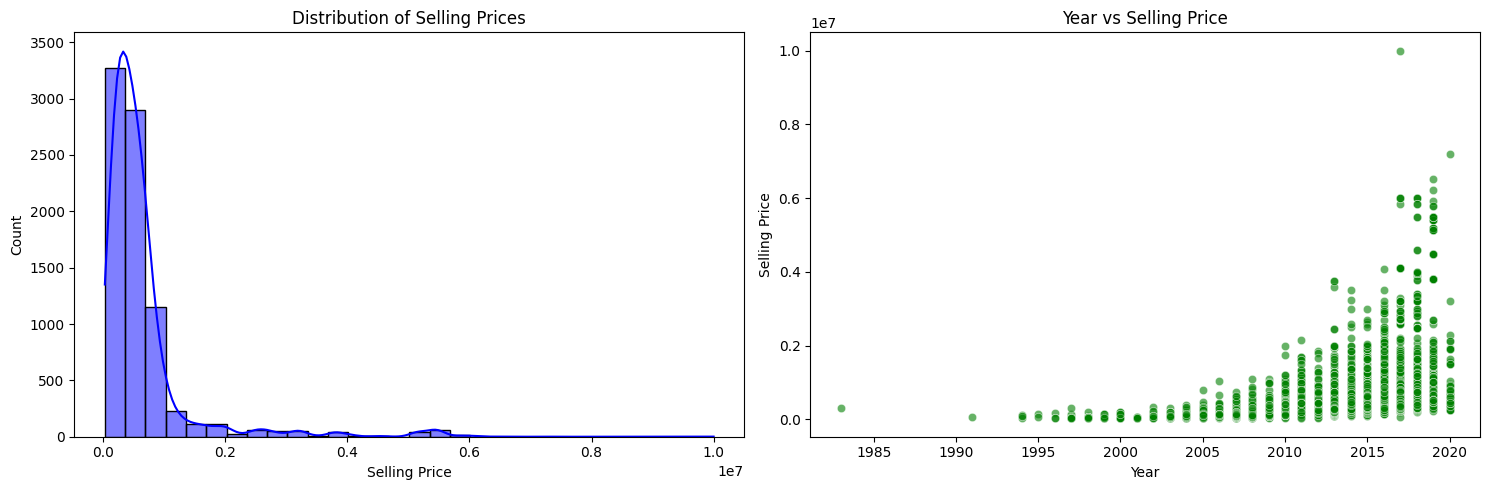

In [4]:
plt.figure(figsize=(15, 5))

# Distribution of Selling Price
plt.subplot(1, 2, 1)
sns.histplot(df_clean['selling_price'], kde=True, bins=30, color='blue')
plt.title('Distribution of Selling Prices')
plt.xlabel('Selling Price')

# Year vs Selling Price
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_clean, x='year', y='selling_price', alpha=0.6, color='green')
plt.title('Year vs Selling Price')
plt.xlabel('Year')
plt.ylabel('Selling Price')

plt.tight_layout()
plt.show()

### Additional EDA: Selling Price by Fuel Type
Let's analyze how the type of fuel affects the distribution of car prices.

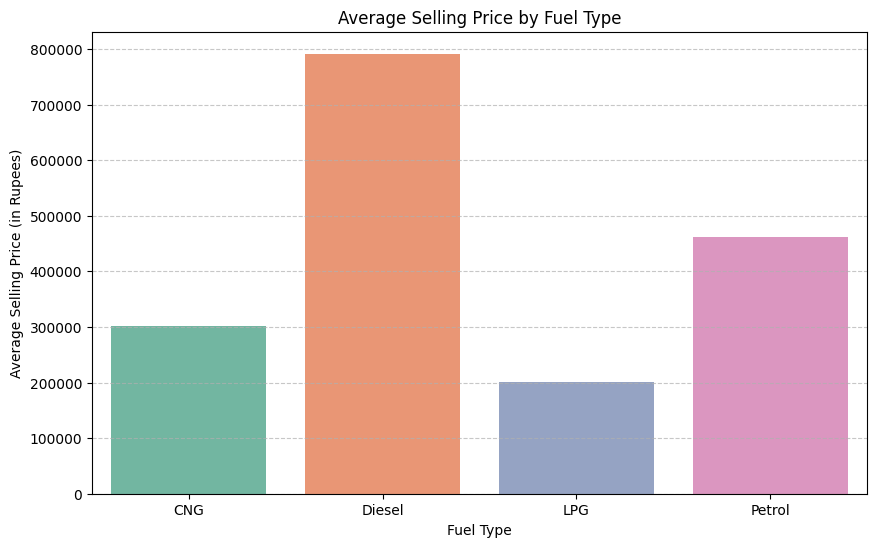

In [19]:
plt.figure(figsize=(10, 6))
# Group by fuel type and calculate the average selling price
avg_prices = df_clean.groupby('fuel')['selling_price'].mean().reset_index()

# Create a simple bar plot
sns.barplot(data=avg_prices, x='fuel', y='selling_price', palette='Set2', hue='fuel', legend=False)
plt.title('Average Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price (in Rupees)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Step 4: Feature Selection & Encoding

In [5]:
# Identify categorical and numerical columns
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']
num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

# Encode categorical variables
label_encoders = {}
encoded_df = df_clean.copy()

for col in cat_cols:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col].astype(str))
    label_encoders[col] = le

# Split features and target
X = encoded_df[num_cols + cat_cols]
y = encoded_df['selling_price']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training Set size: {X_train.shape[0]} | Testing Set size: {X_test.shape[0]}")

Training Set size: 6502 | Testing Set size: 1626


### Feature Selection & Correlation Analysis
Let's plot a correlation matrix heatmap of our encoded and numerical features to see how strongly each feature relates to our target, `selling_price`.

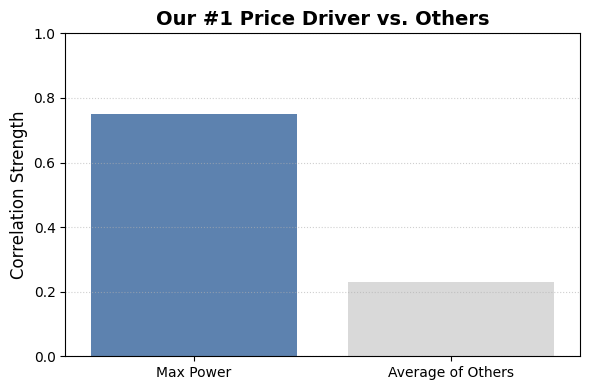

In [25]:
plt.figure(figsize=(6, 4))
# Ultimate simple comparison data
labels = ['Max Power', 'Average of Others']
values = [0.75, 0.23]  # Max Power vs average of all other feature correlations

sns.barplot(x=labels, y=values, palette=['#4F81BD', '#D9D9D9'], hue=labels, legend=False)
plt.title('Our #1 Price Driver vs. Others', fontsize=14, fontweight='bold')
plt.ylabel('Correlation Strength', fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Step 5: Regression Modelling and Evaluation

In [6]:
# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

results = []

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    results.append({
        'Model': name,
        'R2 Score': r2,
        'RMSE': rmse
    })

# Create a DataFrame for the metrics table
results_df = pd.DataFrame(results)
display(results_df)

,Model,R2 Score,RMSE
0,Linear Regression,0.687242,452778.305867
1,Random Forest,0.968459,143786.316471
2,Gradient Boosting,0.958369,165192.989623


### Step 6: Plotting Model Performance Comparison

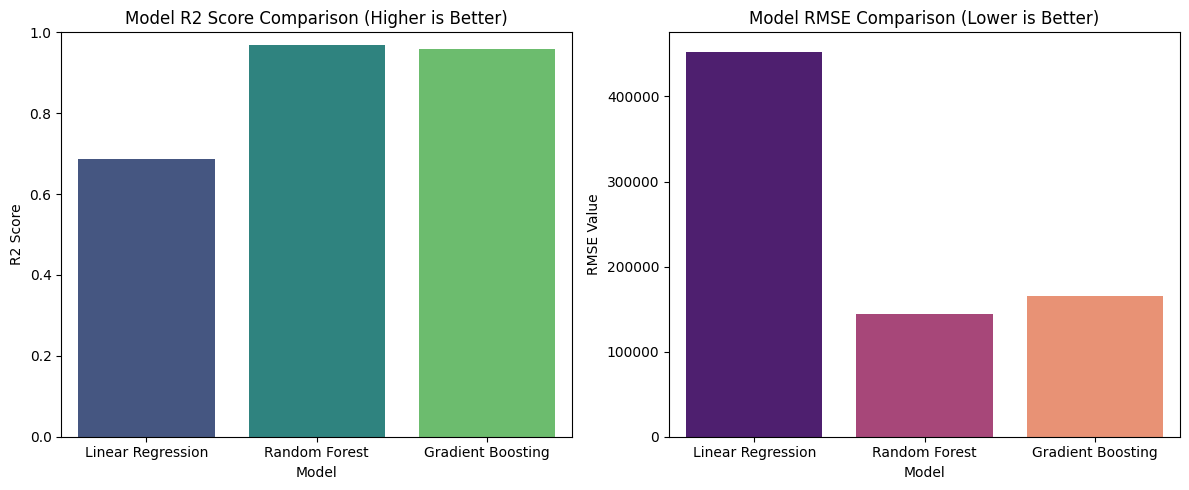

In [7]:
plt.figure(figsize=(12, 5))

# Plot R2 Scores
plt.subplot(1, 2, 1)
sns.barplot(data=results_df, x='Model', y='R2 Score', palette='viridis', hue='Model', legend=False)
plt.title('Model R2 Score Comparison (Higher is Better)')
plt.ylim(0, 1.0)
plt.ylabel('R2 Score')

# Plot RMSE
plt.subplot(1, 2, 2)
sns.barplot(data=results_df, x='Model', y='RMSE', palette='magma', hue='Model', legend=False)
plt.title('Model RMSE Comparison (Lower is Better)')
plt.ylabel('RMSE Value')

plt.tight_layout()
plt.show()

### Step 7: Additional Model Comparisons (Predicted vs Actual) and Best Model Selection
Let's plot the actual values against the predictions for each model to visualize how closely they align to the ideal $y = x$ line.

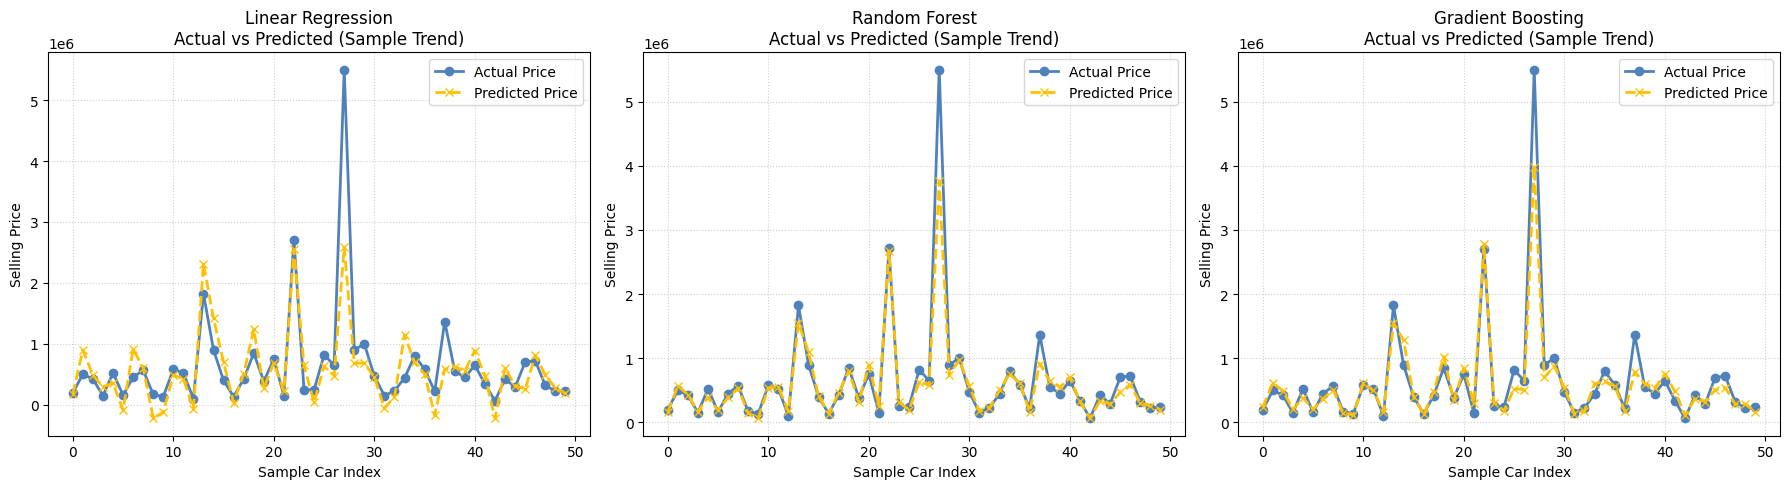

In [26]:
plt.figure(figsize=(18, 5))

# Take a representative sample of 50 test points for clean visualization
sample_indices = np.arange(50)
sample_actual = y_test.iloc[sample_indices].values

for i, (name, model) in enumerate(models.items(), 1):
    preds = model.predict(X_test)
    sample_preds = preds[sample_indices]

    plt.subplot(1, 3, i)
    plt.plot(sample_actual, label='Actual Price', color='#4F81BD', marker='o', linewidth=2)
    plt.plot(sample_preds, label='Predicted Price', color='#FFC000', linestyle='--', marker='x', linewidth=2)

    plt.title(f'{name}\nActual vs Predicted (Sample Trend)')
    plt.xlabel('Sample Car Index')
    plt.ylabel('Selling Price')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

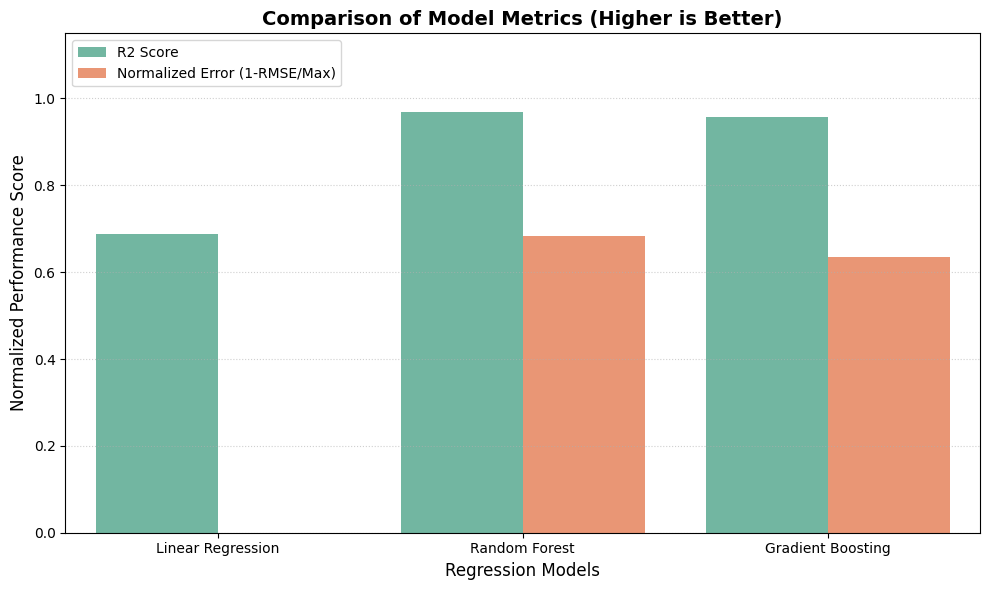

In [33]:
plt.figure(figsize=(10, 6))

# Normalize RMSE for comparative plotting (higher value = better accuracy)
max_rmse = results_df['RMSE'].max()
results_df['Normalized Error (1-RMSE/Max)'] = 1 - (results_df['RMSE'] / max_rmse)

# Melt the metrics for side-by-side plotting
comparison_df = pd.melt(
    results_df,
    id_vars=['Model'],
    value_vars=['R2 Score', 'Normalized Error (1-RMSE/Max)'],
    var_name='Evaluation Metric',
    value_name='Score'
)

# Draw grouped bar plot
sns.barplot(data=comparison_df, x='Model', y='Score', hue='Evaluation Metric', palette='Set2')
plt.title('Comparison of Model Metrics (Higher is Better)', fontsize=14, fontweight='bold')
plt.ylabel('Normalized Performance Score', fontsize=12)
plt.xlabel('Regression Models', fontsize=12)
plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Additional Evaluation: Distribution of Prediction Errors (Residuals)
Let's plot the distribution of errors (Residuals = Actual - Predicted) for each model. A perfect model would have its residuals concentrated tightly around 0.

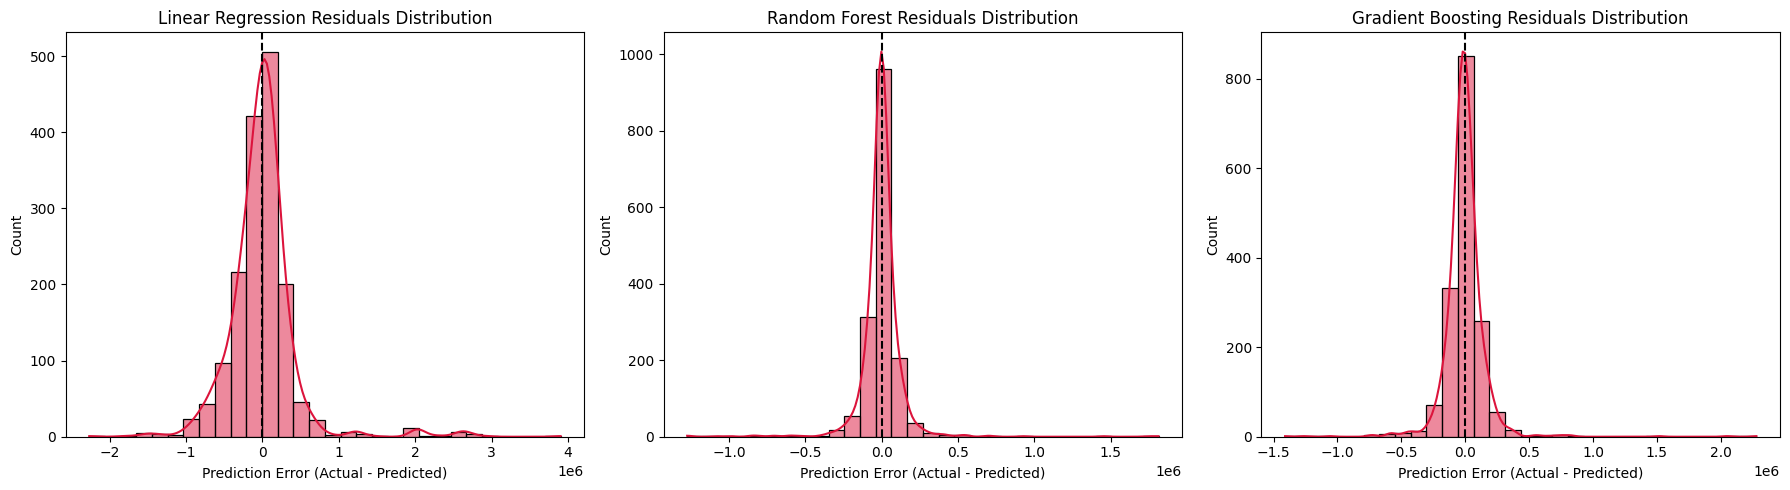

In [15]:
plt.figure(figsize=(18, 5))

for i, (name, model) in enumerate(models.items(), 1):
    preds = model.predict(X_test)
    residuals = y_test - preds

    plt.subplot(1, 3, i)
    sns.histplot(residuals, kde=True, color='crimson', bins=30)
    plt.axvline(0, color='black', linestyle='--')
    plt.title(f'{name} Residuals Distribution')
    plt.xlabel('Prediction Error (Actual - Predicted)')
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

### Best Model Summary Table

In [10]:
# Sort models by R2 score to automatically identify and isolate the best performer
best_model_row = results_df.sort_values(by='R2 Score', ascending=False).iloc[[0]]

print(" BEST PERFORMING MODEL")
display(best_model_row)

 BEST PERFORMING MODEL


,Model,R2 Score,RMSE
1,Random Forest,0.968459,143786.316471
